เริ่มโมเดลแรก — SVM
- เพราะเป็นโมเดล Machine Learning ที่ใช้เป็น Baseline เพื่อเปรียบเทียบกับโมเดล Deep Learning อีก 3 ตัวได้

- SVM ไม่ได้เรียนรู้จากภาพผ่าน Convolution แบบ CNN เราจะต้องแปลงภาพให้เป็นตัวเลขที่แสดงลักษณะสำคัญของกล้วย (Feature Extraction) ก่อน เช่น ลักษณะสีและพื้นผิว

โหลดข้อมูลสำหรับ SVM

In [1]:

#Load dataset for SVM

from pathlib import Path
import pandas as pd
import numpy as np
from PIL import Image, ImageOps

# กำหนดตำแหน่งโปรเจกต์
project_directory = Path(r"C:\BananaRipeness_AI")

manifest_path = (
    project_directory
    / "results"
    / "screened_dataset_manifest.csv"
)

# โหลดข้อมูล
dataset_dataframe = pd.read_csv(manifest_path)

# กำหนดชื่อคลาสและหมายเลขคลาส
class_names = sorted(dataset_dataframe["label"].unique())

class_to_index = {
    class_name: class_index
    for class_index, class_name in enumerate(class_names)
}

# แยก Train และ Validation
train_dataframe = dataset_dataframe[
    dataset_dataframe["split"] == "train"
].reset_index(drop=True)

valid_dataframe = dataset_dataframe[
    dataset_dataframe["split"] == "valid"
].reset_index(drop=True)

print("Train images:", len(train_dataframe))
print("Validation images:", len(valid_dataframe))
print("Number of classes:", len(class_names))
print("Class mapping:", class_to_index)


Train images: 3931
Validation images: 801
Number of classes: 6
Class mapping: {'freshripe': 0, 'freshunripe': 1, 'overripe': 2, 'ripe': 3, 'rotten': 4, 'unripe': 5}


Feature Extraction สำหรับ SVM
- CNN สามารถเรียนรู้ลักษณะของภาพผ่าน Convolution ได้เอง แต่ SVM ต้องได้รับข้อมูลตัวเลขที่บอกลักษณะของภาพก่อน ซึ่งเราเรียกว่า Features

สำหรับกล้วย จะเริ่มด้วย HSV Color Histogram เพราะสีมีความสัมพันธ์กับระดับความสุก

นับการกระจายของแต่ละช่องสีเป็น 16 ช่วง ดังนั้นภาพ 1 ภาพจะมี \(16 \times 3 = 48\) Features

- - - 

ทดลองสกัด Features จากภาพ 1 ภาพ

In [2]:

#  Extract HSV color histogram features

def extract_hsv_features(image_path):

    # 1. เปิดภาพและแปลงเป็น RGB
    with Image.open(image_path) as opened_image:
        original_image = opened_image.convert("RGB")

    # 2. Resize โดยรักษาสัดส่วน
    resized_image = ImageOps.pad(
        original_image,
        size=(224, 224),
        method=Image.Resampling.LANCZOS,
        color=(128, 128, 128)
    )

    # 3. สร้าง Mask เพื่อไม่ให้นับขอบ Padding
    original_mask = Image.new(
        "L", original_image.size, 255
    )

    resized_mask = ImageOps.pad(
        original_mask,
        size=(224, 224),
        method=Image.Resampling.NEAREST,
        color=0
    )

    valid_pixel_mask = np.asarray(resized_mask) > 0

    # 4. แปลงภาพจาก RGB เป็น HSV
    hsv_image = np.asarray(
        resized_image.convert("HSV")
    )

    # 5. คำนวณ Histogram ของ H, S และ V
    histogram_features = []

    for channel_index in range(3):

        channel_pixels = hsv_image[
            :, :, channel_index
        ][valid_pixel_mask]

        histogram_counts, _ = np.histogram(
            channel_pixels,
            bins=16,
            range=(0, 256)
        )

        normalized_histogram = (
            histogram_counts.astype(np.float32)
            / len(channel_pixels)
        )

        histogram_features.extend(
            normalized_histogram
        )

    return np.array(
        histogram_features,
        dtype=np.float32
    )


# ทดลองกับภาพ Train ภาพแรก
sample_image_path = train_dataframe.iloc[0]["image_path"]

sample_features = extract_hsv_features(sample_image_path)

print("Feature shape:", sample_features.shape)
print("Number of features:", len(sample_features))
print("First 10 features:", sample_features[:10])


Feature shape: (48,)
Number of features: 48
First 10 features: [0.13961522 0.22321428 0.00292304 0.00066433 0.00077062 0.00308248
 0.00318878 0.01094813 0.27370322 0.3202062 ]


- - ImageOps.pad()	ปรับภาพเป็น 224 × 224 โดยไม่บิดสัดส่วน
- - original_mask	สร้างพื้นที่ระบุว่าอะไรคือส่วนของภาพจริง
- - valid_pixel_mask	ไม่นับขอบสีเทาที่ Padding เพิ่มเข้าไป
- - .convert("HSV")	แปลงภาพเป็นระบบสี HSV
- - np.histogram(..., bins=16)	แบ่งค่าของแต่ละช่องสีเป็น 16 ช่วง
- - / len(channel_pixels)	เปลี่ยนจำนวนพิกเซลเป็นสัดส่วน
- - np.array()	สร้าง Feature Vector สำหรับ SVM

ค่า Features ทั้ง 10 ตัวจะขึ้นอยู่กับภาพที่เลือก

ทำไมต้องมี Mask? เพราะเราเพิ่มขอบสีเทาให้ภาพตอน Resize หากนับขอบเหล่านั้นรวมไปด้วย SVM อาจเรียนรู้ลักษณะของ Padding แทนสีของกล้วย

อย่างไรก็ตาม Histogram นี้ยังรวมพื้นหลังเดิมของภาพอยู่ด้วย จึงใช้เป็น Color Baseline ก่อน และสามารถเพิ่ม Texture Features เพื่อช่วยแยกกล้วยที่มีจุดดำหรือผิวเน่าในขั้นต่อไปได้

ตัวอย่างค่า 0.13961522 หมายถึงประมาณ 13.96% ของพิกเซลในพื้นที่ภาพที่นำมาคำนวณ อยู่ในช่วง Hue แรก ไม่ได้หมายถึงโมเดลทำนายถูก 13.96%

- - -

สกัด Features ของ Train และ Validation ทั้งหมด
- เคยทดลองเพียง 1 ภาพ ต่อไปจะนำฟังก์ชัน extract_hsv_features() ที่สร้างไว้มาใช้กับข้อมูลทั้งสองชุด

In [3]:

# Extract HSV features for Train and Validation

import numpy as np

# สร้างฟังก์ชันสกัด Features จากหลายภาพ
def extract_feature_matrix(dataframe, dataset_name):

    feature_matrix = np.empty(
        (len(dataframe), 48),
        dtype=np.float32
    )

    for image_index, image_path in enumerate(
        dataframe["image_path"]
    ):

        feature_matrix[image_index] = (
            extract_hsv_features(image_path)
        )

        # แสดงความคืบหน้าทุก 500 ภาพ
        if (image_index + 1) % 500 == 0:
            print(
                f"{dataset_name}: "
                f"{image_index + 1}/{len(dataframe)} images"
            )

    return feature_matrix


# สกัด Features ของ Train
train_features = extract_feature_matrix(
    train_dataframe,
    "Train"
)

# สกัด Features ของ Validation
valid_features = extract_feature_matrix(
    valid_dataframe,
    "Validation"
)

# แปลง Label เป็นตัวเลข
train_labels = (
    train_dataframe["label"]
    .map(class_to_index)
    .to_numpy(dtype=np.int32)
)

valid_labels = (
    valid_dataframe["label"]
    .map(class_to_index)
    .to_numpy(dtype=np.int32)
)

# ตรวจสอบผลลัพธ์
print("\nTrain features:", train_features.shape)
print("Train labels:", train_labels.shape)

print("Validation features:", valid_features.shape)
print("Validation labels:", valid_labels.shape)


Train: 500/3931 images
Train: 1000/3931 images
Train: 1500/3931 images
Train: 2000/3931 images
Train: 2500/3931 images
Train: 3000/3931 images
Train: 3500/3931 images
Validation: 500/801 images

Train features: (3931, 48)
Train labels: (3931,)
Validation features: (801, 48)
Validation labels: (801,)


หมายความว่าแต่ละภาพถูกแปลงเป็นตัวเลข 48 ค่า ซึ่งประกอบด้วย HSV Histogram ของ H, S และ V อย่างละ 16 ค่า

- - np.empty((len(dataframe), 48))	จองพื้นที่สำหรับเก็บ 48 Features ต่อภาพ
- - enumerate()	วนอ่านภาพพร้อมหมายเลขลำดับ
- - extract_hsv_features()	เรียกฟังก์ชันที่หนูสร้างไว้แล้ว
- - feature_matrix[image_index]	บันทึก Features ของภาพลงแถวที่ตรงกัน
- - % 500 == 0	แสดงความคืบหน้าทุก 500 ภาพ
- - .map(class_to_index)	เปลี่ยนชื่อคลาสเป็นตัวเลข 0–5

Feature Scaling ด้วย StandardScaler
- ก่อนส่ง Features เข้า SVM เราจะปรับสเกลด้วย StandardScaler เพื่อให้แต่ละ Feature มีระดับค่าที่เหมาะสมต่อการคำนวณระยะห่างของ SVM


StandardScaler

In [5]:
%pip install scikit-learn

  Using cached scipy-1.17.1-cp311-cp311-win_amd64.whl.metadata (60 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
   ---------------------------------------- 0.0/8.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.3 MB 1.9 MB/s eta 0:00:05
   ---------------------------------------- 0.1/8.3 MB 648.1 kB/s eta 0:00:13
    --------------------------------------- 0.1/8.3 MB 654.9 kB/s eta 0:00:13
   - -------------------------------------- 0.2/8.3 MB 1.0 MB/s eta 0:00:08
   - -------------------------------------- 0.3/8.3 MB 923.9 kB/s eta 0:00:09
   -- ------------------------------------- 0.5/8.3 MB 1.5 MB/s eta 0:00:06
   -- ------------------------------------- 0.5/8.3 MB 1.6 MB/s eta 0:00:05
   --- ------------------------------------ 0.8/8.3 MB 2.0 MB/s eta 0:00:04
   ---- ----------------------------------- 1.0/8.3 MB 2.4 MB/s eta 0:00:04
   -------- ------------------------------- 1.7/8.3 MB 3.4 MB/s eta 0:00:02
   ---------- ------------


[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [6]:

#  Standardize HSV features for SVM

from sklearn.preprocessing import StandardScaler
import numpy as np

# สร้าง StandardScaler
feature_scaler = StandardScaler()

# เรียนรู้ค่าเฉลี่ยและส่วนเบี่ยงเบนจาก Train เท่านั้น
train_scaled_features = feature_scaler.fit_transform(
    train_features
)

# ใช้ค่าจาก Train มาแปลง Validation
valid_scaled_features = feature_scaler.transform(
    valid_features
)

# ตรวจสอบผลลัพธ์
print("Train scaled shape:", train_scaled_features.shape)
print("Validation scaled shape:", valid_scaled_features.shape)

print(
    "First 5 feature means:",
    np.round(train_scaled_features.mean(axis=0)[:5], 4)
)

print(
    "First 5 feature standard deviations:",
    np.round(train_scaled_features.std(axis=0)[:5], 4)
)


Train scaled shape: (3931, 48)
Validation scaled shape: (801, 48)
First 5 feature means: [0. 0. 0. 0. 0.]
First 5 feature standard deviations: [1. 1. 1. 1. 1.]


- - StandardScaler()	สร้างเครื่องมือปรับสเกล
- - fit_transform(train_features)	เรียนรู้ค่าทางสถิติจาก Train และแปลง Train
- - transform(valid_features)	ใช้ค่าที่เรียนรู้จาก Train มาแปลง Validation
- - mean(axis=0)	หาค่าเฉลี่ยของแต่ละ Feature
- - std(axis=0)	หาส่วนเบี่ยงเบนมาตรฐานของแต่ละ Feature

ไม่ใช้ fit_transform() กับ Validation เพราะจะทำให้กระบวนการเตรียมข้อมูลเรียนรู้สถิติจากชุดประเมินได้ เราจึงใช้ transform()

- -  -

เริ่มเทรนโมเดล SVM
- SVM ย่อมาจาก Support Vector Machine เป็นอัลกอริทึมที่พยายามหาเส้นหรือขอบเขตสำหรับแยกคลาสออกจากกัน

- สำหรับข้อมูลภาพกล้วย เลือกใช้ RBF Kernel เพราะความสัมพันธ์ระหว่างสีของกล้วยกับระดับความสุกอาจไม่ได้แบ่งแยกกันเป็นเส้นตรง

- kernel	กำหนดค่า rbf	.:เรียนรู้ขอบเขตที่ไม่เป็นเส้นตรง
- C	กำหนดค่า 1.0	:ค่าตั้งต้นสำหรับควบคุม Regularization
- gamma	 กำหนดค่า scale	:คำนวณตามข้อมูล Features
- class_weight	กำหนดค่า balanced	:ช่วยลดผลกระทบจาก Class Imbalance

Train SVM และประเมิน Validation เบื้องต้น

In [7]:

# Train SVM with RBF kernel

import time
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score

# 1. สร้างโมเดล SVM
svm_model = SVC(
    kernel="rbf",
    C=1.0,
    gamma="scale",
    class_weight="balanced"
)

# 2. เริ่มจับเวลา
training_start_time = time.perf_counter()

# 3. เทรนด้วยข้อมูล Train เท่านั้น
svm_model.fit(
    train_scaled_features,
    train_labels
)

# 4. คำนวณเวลาที่ใช้เทรน
training_time = (
    time.perf_counter() - training_start_time
)

# 5. ทำนายข้อมูล Validation
valid_predictions = svm_model.predict(
    valid_scaled_features
)

# 6. ประเมินผลเบื้องต้น
validation_accuracy = accuracy_score(
    valid_labels,
    valid_predictions
)

validation_macro_f1 = f1_score(
    valid_labels,
    valid_predictions,
    average="macro"
)

print("SVM Training Completed")
print(f"Training time: {training_time:.2f} seconds")
print(f"Validation Accuracy: {validation_accuracy:.4f}")
print(f"Validation Macro-F1: {validation_macro_f1:.4f}")
print("Support vectors:", len(svm_model.support_))


SVM Training Completed
Training time: 0.28 seconds
Validation Accuracy: 0.9476
Validation Macro-F1: 0.9307
Support vectors: 1700


- - SVC() สร้างโมเดล SVM สำหรับจำแนกประเภท
- - .fit() ให้โมเดลเรียนรู้จาก Features และ Labels ของ Train
- - time.perf_counter() จับเวลาการเทรน เพื่อใช้เปรียบเทียบกับโมเดลอื่น
- - .predict() ให้โมเดลทำนายคลาสของภาพ Validation
-  - accuracy_score() วัดสัดส่วนภาพที่ทำนายถูก
- - f1_score(average="macro") คำนวณ F1 ของแต่ละคลาสแล้วเฉลี่ยแบบให้น้ำหนักเท่ากัน เหมาะกับ Dataset ที่มี Class Imbalance
- - support_ เก็บดัชนีของภาพ Train ที่เป็น Support Vectors ซึ่งมีบทบาทในการกำหนดขอบเขตการจำแนก

-- - 

Accuracy 94.76% — SVM ทำนายภาพ Validation ถูกประมาณ 95 จากทุก 100 ภาพ



Macro-F1 93.07% — เมื่อให้ความสำคัญกับทั้ง 6 คลาสเท่ากัน ผลยังค่อนข้างสูง ซึ่งสำคัญเพราะข้อมูลของเราไม่สมดุล



Training Time 0.28 วินาที — เทรน SVM ได้เร็วมาก แต่เวลานี้ยังไม่รวม Feature Extraction และ StandardScaler



Support Vectors 1,700 — จำนวนตัวอย่างที่ SVM ใช้ในการกำหนดขอบเขตการจำแนก

- - -

Classification Report และ Confusion Matrix
- โดยเฉพาะ unripe ซึ่งมีข้อมูลน้อย และ freshripe กับ ripe ที่อาจมีลักษณะใกล้เคียงกัน

SVM Classification Report
              precision    recall  f1-score   support

   freshripe     0.9603    0.9477    0.9539       153
 freshunripe     1.0000    1.0000    1.0000        92
    overripe     0.9740    0.9494    0.9615       158
        ripe     0.8611    0.9588    0.9073        97
      rotten     0.9698    0.9245    0.9466       278
      unripe     0.7097    0.9565    0.8148        23

    accuracy                         0.9476       801
   macro avg     0.9125    0.9561    0.9307       801
weighted avg     0.9517    0.9476    0.9485       801



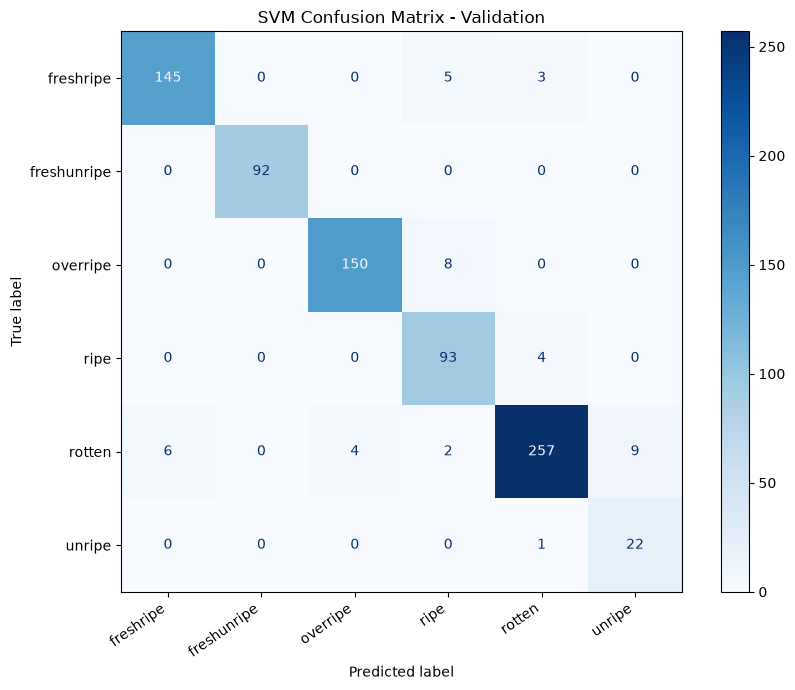

In [8]:

#  Classification Report and Confusion Matrix

import matplotlib.pyplot as plt
from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay
)

# แสดง Precision, Recall และ F1-score ของทุกคลาส
print("SVM Classification Report")
print(
    classification_report(
        valid_labels,
        valid_predictions,
        labels=list(range(len(class_names))),
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)

# สร้างกราฟ Confusion Matrix
figure, graph = plt.subplots(figsize=(9, 7))

ConfusionMatrixDisplay.from_predictions(
    valid_labels,
    valid_predictions,
    labels=list(range(len(class_names))),
    display_labels=class_names,
    cmap="Blues",
    values_format="d",
    ax=graph
)

graph.set_title("SVM Confusion Matrix - Validation")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()

# บันทึกกราฟสำหรับรายงาน
figure.savefig(
    project_directory / "results" / "svm_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


- classification_report()	แสดง Precision, Recall, F1 และ Support แยกตามคลาส
- ConfusionMatrixDisplay.from_predictions()	สร้างตารางภาพแสดงผลทำนายจริงเทียบกับที่โมเดลทำนาย
- labels=list(range(...))	กำหนดลำดับคลาส 0–5 ให้ตรงกัน
- cmap="Blues"	ใช้โทนสีน้ำเงินในกราฟ
- values_format="d"	แสดงจำนวนภาพเป็นจำนวนเต็ม
- figure.savefig()	บันทึกกราฟ PNG สำหรับรายงาน

 วิธีอ่าน Confusion Matrix: แนวตั้งคือคลาสจริง แนวนอนคือคลาสที่โมเดลทำนาย ตัวเลขบนแนวทแยงคือภาพที่ทำนายถูก ส่วนตัวเลขนอกแนวทแยงคือภาพที่ทำนายผิด

-  - - - 

1. freshunripe ได้ F1 = 1.0000

โมเดลทำนายถูกครบทั้ง 92 ภาพใน Validation และไม่มีภาพจากคลาสอื่นถูกทำนายเป็น freshunripe เลย ถือเป็นผลที่ดี แต่ยังไม่รับประกันว่าจะถูก 100% กับภาพใหม่

2. unripe เป็นคลาสที่มี F1 ต่ำที่สุด
- Precision = 70.97%
- Recall = 95.65%
- F1 = 81.48%
หมายความว่าโมเดลตรวจพบ unripe จริงได้ 22 จาก 23 ภาพ แต่มีภาพจากคลาสอื่นอีกประมาณ 9 ภาพที่ถูกทำนายผิดเป็น unripe

จุดอ่อนจึงไม่ใช่การตรวจไม่เจอ unripe แต่เป็นการทำนายคลาสอื่นให้กลายเป็น unripe มากเกินไป

3. ripe มี Precision ค่อนข้างต่ำ

Precision = 86.11% แต่ Recall = 95.88% แสดงว่าโมเดลตรวจพบ ripe ได้ดี แต่ยังทำนายภาพจากคลาสอื่นเป็น ripe อยู่บ้าง

4. rotten มีจำนวนภาพที่ทำนายผิดมากที่สุดในเชิงจำนวน

Recall = 92.45% หมายความว่าทำนายถูก 257 จาก 278 ภาพ และพลาดไป 21 ภาพ

สรุปคือโมเดลทำนายถูก 759 จาก 801 ภาพ แต่เราต้องดู Confusion Matrix เพิ่มว่า 42 ภาพที่ผิดนั้นสับสนระหว่างคลาสใดบ้าง

- - - 

ปรับ Hyperparameters ของ SVM

- มี SVM ตัวตั้งต้นแล้ว ต่อไปจะทดลองหลายค่าของ C, gamma และ class_weight เพื่อดูว่าปรับ Validation Macro-F1 ให้สูงขึ้นได้หรือไม่

In [9]:

# Tune SVM hyperparameters

import time
import pandas as pd

from sklearn.svm import SVC
from sklearn.model_selection import ParameterGrid
from sklearn.metrics import accuracy_score, f1_score

# กำหนดค่าที่ต้องการทดลอง
parameter_options = {
    "C": [0.1, 1.0, 10.0],
    "gamma": ["scale", 0.1],
    "class_weight": [None, "balanced"]
}

experiment_results = []

best_macro_f1 = -1.0
best_svm_model = None
best_svm_parameters = None

for parameters in ParameterGrid(parameter_options):

    candidate_model = SVC(
        kernel="rbf",
        **parameters
    )

    training_start_time = time.perf_counter()

    candidate_model.fit(
        train_scaled_features,
        train_labels
    )

    candidate_training_time = (
        time.perf_counter() - training_start_time
    )

    candidate_predictions = candidate_model.predict(
        valid_scaled_features
    )

    candidate_accuracy = accuracy_score(
        valid_labels,
        candidate_predictions
    )

    candidate_macro_f1 = f1_score(
        valid_labels,
        candidate_predictions,
        average="macro"
    )

    experiment_results.append({
        **parameters,
        "accuracy": candidate_accuracy,
        "macro_f1": candidate_macro_f1,
        "training_time": candidate_training_time
    })

    if candidate_macro_f1 > best_macro_f1:
        best_macro_f1 = candidate_macro_f1
        best_svm_model = candidate_model
        best_svm_parameters = parameters.copy()

# สรุปผลการทดลอง
svm_experiment_dataframe = pd.DataFrame(
    experiment_results
).sort_values(
    by=["macro_f1", "accuracy"],
    ascending=False
).reset_index(drop=True)

print("Total experiments:", len(experiment_results))
print("Best parameters:", best_svm_parameters)
print(f"Best Validation Macro-F1: {best_macro_f1:.4f}")

display(svm_experiment_dataframe)


Total experiments: 12
Best parameters: {'C': 10.0, 'class_weight': 'balanced', 'gamma': 'scale'}
Best Validation Macro-F1: 0.9677


,C,class_weight,gamma,accuracy,macro_f1,training_time
0,10.0,balanced,scale,0.976280,0.967735,0.392957
1,10.0,NaN,scale,0.973783,0.965819,0.176965
2,10.0,NaN,0.1,0.966292,0.956114,0.442195
3,10.0,balanced,0.1,0.963795,0.950995,0.468717
4,1.0,balanced,0.1,0.962547,0.950277,0.443690
5,1.0,NaN,0.1,0.957553,0.944215,0.461695
6,1.0,NaN,scale,0.958801,0.943976,0.196022
7,1.0,balanced,scale,0.947566,0.930702,0.247335
8,0.1,balanced,0.1,0.897628,0.866912,0.626639
9,0.1,balanced,scale,0.832709,0.814677,0.439465


-  - ParameterGrid()	สร้างชุดค่าที่ต้องทดลองทั้งหมด
- - C	ควบคุมระดับ Regularization
- - gamma	ควบคุมอิทธิพลของตัวอย่างใน RBF Kernel
- - class_weight	เปรียบเทียบการใช้และไม่ใช้การถ่วงน้ำหนักคลาส
- - candidate_model.fit()	เทรน SVM ด้วยค่าแต่ละชุด
- - best_macro_f1	เก็บคะแนน Macro-F1 ที่ดีที่สุด
-  - best_svm_model	เก็บโมเดลที่ให้ Macro-F1 สูงที่สุด

โมเดลที่ปรับแล้วทำนายถูกเพิ่มขึ้น 23 ภาพ และ Macro-F1 เพิ่มขึ้นประมาณ 3.70 จุดเปอร์เซ็นต์

ข้อสังเกตเพิ่มเติมคือ class_weight ที่แสดงเป็น NaN ในตาราง หมายถึงค่าที่ตั้งไว้เป็น None แล้ว pandas แสดงเป็นค่าว่าง ไม่ใช่ว่าการทดลองนั้นผิดพลาด

- - -

ประเมิน Best SVM และสร้าง Confusion Matrix

Best SVM Classification Report
              precision    recall  f1-score   support

   freshripe     0.9934    0.9804    0.9868       153
 freshunripe     1.0000    1.0000    1.0000        92
    overripe     0.9805    0.9557    0.9679       158
        ripe     0.9314    0.9794    0.9548        97
      rotten     0.9819    0.9784    0.9802       278
      unripe     0.8800    0.9565    0.9167        23

    accuracy                         0.9763       801
   macro avg     0.9612    0.9751    0.9677       801
weighted avg     0.9769    0.9763    0.9764       801

Accuracy: 0.9763
Macro-F1: 0.9677


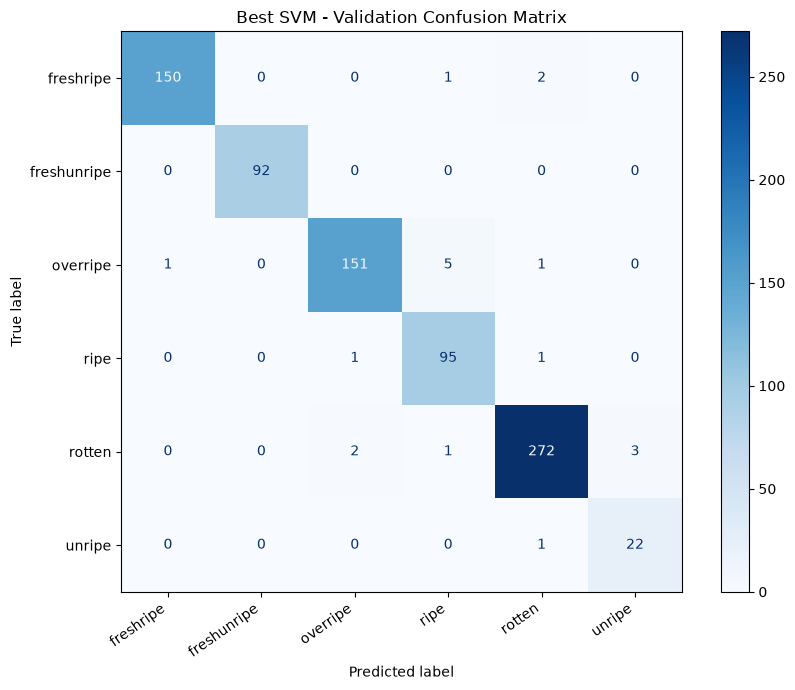

In [10]:

#  Evaluate Best SVM on Validation

import matplotlib.pyplot as plt
from sklearn.metrics import (
    classification_report,
    accuracy_score,
    f1_score,
    ConfusionMatrixDisplay
)

# 1. ใช้โมเดลที่ดีที่สุดทำนาย Validation
best_valid_predictions = best_svm_model.predict(
    valid_scaled_features
)

# 2. คำนวณผลประเมิน
best_validation_accuracy = accuracy_score(
    valid_labels,
    best_valid_predictions
)

best_validation_macro_f1 = f1_score(
    valid_labels,
    best_valid_predictions,
    average="macro"
)

# 3. แสดงผล
print("Best SVM Classification Report")
print(
    classification_report(
        valid_labels,
        best_valid_predictions,
        labels=list(range(len(class_names))),
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)

print(f"Accuracy: {best_validation_accuracy:.4f}")
print(f"Macro-F1: {best_validation_macro_f1:.4f}")

# 4. สร้าง Confusion Matrix
figure, graph = plt.subplots(figsize=(9, 7))

ConfusionMatrixDisplay.from_predictions(
    valid_labels,
    best_valid_predictions,
    labels=list(range(len(class_names))),
    display_labels=class_names,
    cmap="Blues",
    values_format="d",
    ax=graph
)

graph.set_title("Best SVM - Validation Confusion Matrix")

plt.xticks(rotation=35, ha="right")
plt.tight_layout()

# 5. บันทึกกราฟ
figure.savefig(
    project_directory / "results" / "best_svm_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


สิ่งที่น่าสนใจคือ unripe ซึ่งเคยมี F1 เพียง 81.48% ตอนนี้เพิ่มเป็น 91.67% โดยตรวจพบถูก 22 จาก 23 ภาพ และมีภาพคลาสอื่นเพียง 3 ภาพที่ถูกทำนายเป็น unripe

-  -- 

สร้างกราฟ Hyperparameter Tuning
- เก็บกราฟการทดลองครบทั้ง 12 รูปแบบไว้ในรายงาน เพื่อแสดงว่าเราเลือก Best SVM จากผลการทดลองจริง ไม่ใช่เลือกค่า C โดยไม่มีหลักฐาน

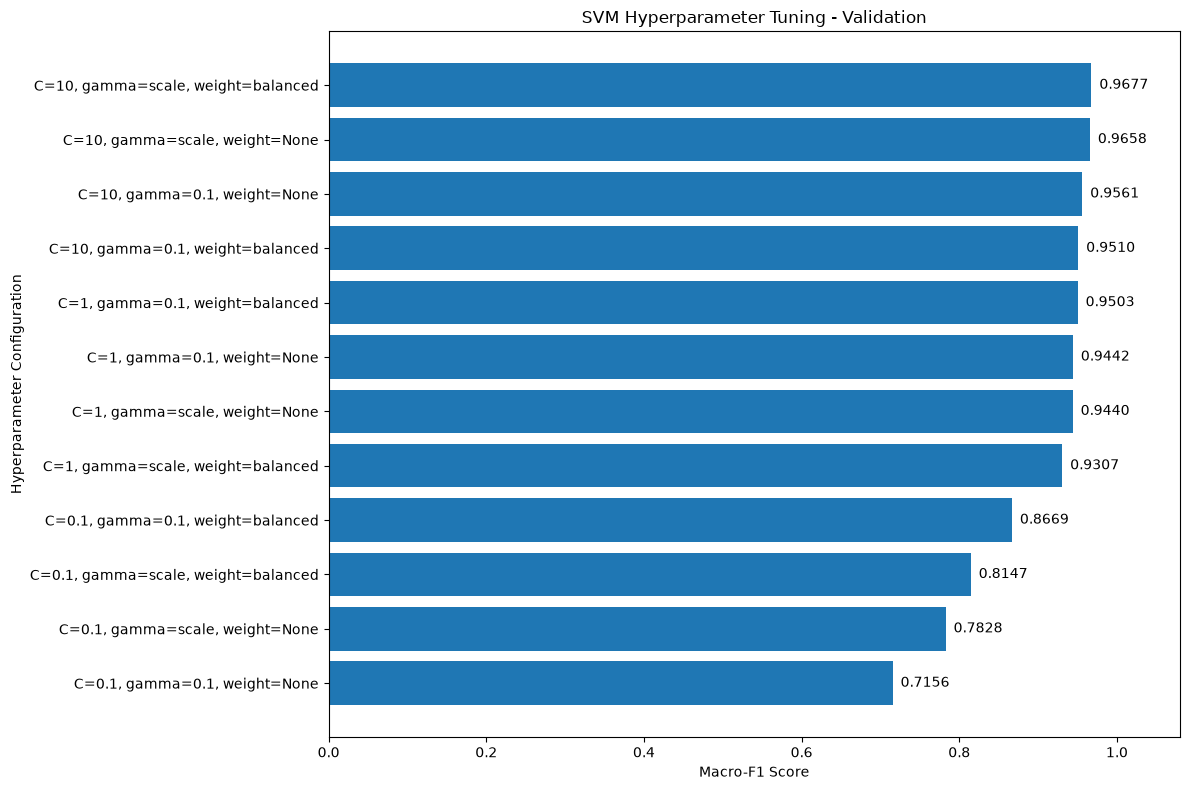

Saved tuning results and graph successfully


In [11]:

#  Visualize SVM Hyperparameter Tuning

import pandas as pd
import matplotlib.pyplot as plt

# เตรียมชื่อแต่ละการทดลองสำหรับกราฟ
experiment_labels = []

for _, experiment in svm_experiment_dataframe.iterrows():

    weight_name = (
        "None"
        if pd.isna(experiment["class_weight"])
        else str(experiment["class_weight"])
    )

    experiment_label = (
        f"C={experiment['C']:g}, "
        f"gamma={experiment['gamma']}, "
        f"weight={weight_name}"
    )

    experiment_labels.append(experiment_label)

# สร้างกราฟ Macro-F1 ทั้ง 12 การทดลอง
figure, graph = plt.subplots(figsize=(12, 8))

graph.barh(
    experiment_labels,
    svm_experiment_dataframe["macro_f1"]
)

graph.invert_yaxis()

graph.set_title("SVM Hyperparameter Tuning - Validation")
graph.set_xlabel("Macro-F1 Score")
graph.set_ylabel("Hyperparameter Configuration")
graph.set_xlim(0, 1.08)

# แสดงค่าคะแนนบนแท่งกราฟ
for experiment_index, macro_f1_score in enumerate(
    svm_experiment_dataframe["macro_f1"]
):
    graph.text(
        macro_f1_score + 0.01,
        experiment_index,
        f"{macro_f1_score:.4f}",
        va="center"
    )

plt.tight_layout()

# บันทึกผลการทดลองและกราฟ
results_directory = project_directory / "results"
results_directory.mkdir(parents=True, exist_ok=True)

svm_experiment_dataframe.to_csv(
    results_directory / "svm_tuning_results.csv",
    index=False
)

figure.savefig(
    results_directory / "svm_hyperparameter_tuning.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved tuning results and graph successfully")


- - .iterrows()	อ่านข้อมูลการทดลองทีละแถว
- - pd.isna()	ตรวจค่า NaN ซึ่งในที่นี้แทน class_weight=None
- - graph.barh()	สร้างกราฟแท่งแนวนอน
- - graph.invert_yaxis()	ให้โมเดลที่คะแนนดีที่สุดอยู่ด้านบน
- - graph.text()	แสดงคะแนน Macro-F1 บนกราฟ
- - .to_csv()	บันทึกตารางผลการทดลอง
- - .savefig()	บันทึกภาพกราฟสำหรับรายงาน

โมเดลที่ดีที่สุด: C=10, gamma=scale, class_weight=balanced ได้ Macro-F1 = 0.9677



อันดับสอง: C=10, gamma=scale, class_weight=None ได้ Macro-F1 = 0.9658 ซึ่งใกล้เคียงอันดับแรกมาก



C=0.1: ผลค่อนข้างต่ำเมื่อเทียบกับ C=1 และ C=10 ในชุดทดลองนี้



การใช้ Class Weight: ไม่ได้ทำให้ผลดีขึ้นทุกกรณี แต่ช่วยให้ชุดค่าที่ดีที่สุดได้คะแนนสูงสุด

- - --

บันทึก Best SVM
- เก็บโมเดลที่เทรนสำเร็จไว้ เพื่อไม่ต้องเทรน SVM ใหม่ทุกครั้งที่เปิด

In [12]:

#  Save Best SVM model and scaler

import joblib
import numpy as np

# 1. กำหนดโฟลเดอร์เก็บโมเดล
models_directory = project_directory / "models"
models_directory.mkdir(parents=True, exist_ok=True)

# 2. เตรียมข้อมูลที่ต้องบันทึก
svm_model_bundle = {
    "model": best_svm_model,
    "scaler": feature_scaler,
    "class_names": class_names,
    "best_parameters": best_svm_parameters,
    "feature_config": {
        "method": "HSV Histogram",
        "bins_per_channel": 16,
        "image_size": (224, 224),
        "padding_color": (128, 128, 128)
    }
}

# 3. บันทึกโมเดล
model_path = models_directory / "svm_hsv_best.joblib"

joblib.dump(svm_model_bundle, model_path)

# 4. โหลดกลับมาทดสอบ
loaded_bundle = joblib.load(model_path)

loaded_predictions = loaded_bundle["model"].predict(
    loaded_bundle["scaler"].transform(valid_features)
)

# 5. ตรวจว่าผลทำนายยังเหมือนเดิม
predictions_match = np.array_equal(
    best_valid_predictions,
    loaded_predictions
)

print("Model saved:", model_path)
print("Model loaded successfully")
print("Predictions match:", predictions_match)
print("Classes:", loaded_bundle["class_names"])


Model saved: C:\BananaRipeness_AI\models\svm_hsv_best.joblib
Model loaded successfully
Predictions match: True
Classes: ['freshripe', 'freshunripe', 'overripe', 'ripe', 'rotten', 'unripe']


- - joblib.dump()	บันทึกโมเดลและ Scaler ลงไฟล์
- - joblib.load()	โหลดโมเดลที่บันทึกกลับมา
- - svm_model_bundle	รวมโมเดล Scaler และข้อมูลการตั้งค่าไว้ด้วยกัน
- - np.array_equal()	ตรวจว่าผลทำนายก่อนและหลังบันทึกตรงกันหรือไม่